# skin 고정 threshold 스윕 — 0.5 / 0.3 / 0.2 / 0.1

**배경**: 팀원이 "RF + descriptor + threshold=0.10 + 20회 반복"을 제안했고, "결국 양성 데이터를
더 구하는 것 외엔 답이 없다"는 결론을 공유했습니다(제 PDF 보고서 결론과 독립적으로 일치).

모델을 RF로 바꾸는 건 하지 않지만(지금 채택한 신경망+Early Stopping 구조가 이미 검증됨),
**"threshold를 낮추면 Sensitivity가 오르는지"는 지금 파이프라인 그대로 바로 확인 가능**합니다.

**주의**: 2026-10-31에 "threshold는 0.5 유지"로 결정한 건 *검증셋마다 새로 고른 threshold가
0.05~0.95로 불안정했기 때문*(nested 방식)입니다. 이번엔 **고정값 하나를 미리 정해서** 반복평가로
검증하는 것이라 방법론이 다릅니다 — 이것도 노이즈인지 진짜 개선인지 반복 10회로 확인합니다.

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\eval_b")
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")

import numpy as np
import matplotlib.pyplot as plt
import bharness as B

ds = B.load_skin()
cfg = dict(B.BASE, lr=0.001, num_hidden_layers=1, dropout=0.0)
print(f"skin: {len(ds)}건, feature {ds.input_dim}차원, 고정 설정: {cfg}")

skin: 541건, feature 2266차원, 고정 설정: {'hidden_dim': 128, 'lr': 0.001, 'num_hidden_layers': 1, 'dropout': 0.0, 'max_epochs': 200, 'patience': 15, 'batch_size': 32, 'val_size': 0.2}


## threshold 0.5 / 0.3 / 0.2 / 0.1을 nz20(현재 채택 feature)로 반복 10회 group 5-fold

In [2]:
THRESHOLDS = [0.5, 0.3, 0.2, 0.1]

store = {}
for th in THRESHOLDS:
    rows = B.repeat_cv(ds, "nz20", n_repeats=10, cfg=cfg, group_aware_val=True, threshold=th)
    store[th] = rows
    a = B.agg(rows)
    print(B.fmt_agg(a, f"threshold={th}"))

threshold=0.5            Sens 0.610±0.073 Spec 0.727±0.030 격차 0.127±0.065 MCC 0.170±0.039 AUC 0.722±0.030
threshold=0.3            Sens 0.797±0.043 Spec 0.507±0.053 격차 0.289±0.074 MCC 0.140±0.028 AUC 0.722±0.030
threshold=0.2            Sens 0.833±0.045 Spec 0.372±0.064 격차 0.461±0.086 MCC 0.098±0.031 AUC 0.722±0.030
threshold=0.1            Sens 0.903±0.060 Spec 0.241±0.062 격차 0.662±0.121 MCC 0.080±0.010 AUC 0.722±0.030


## 시각화 — threshold별 Sensitivity/Specificity/MCC 변화

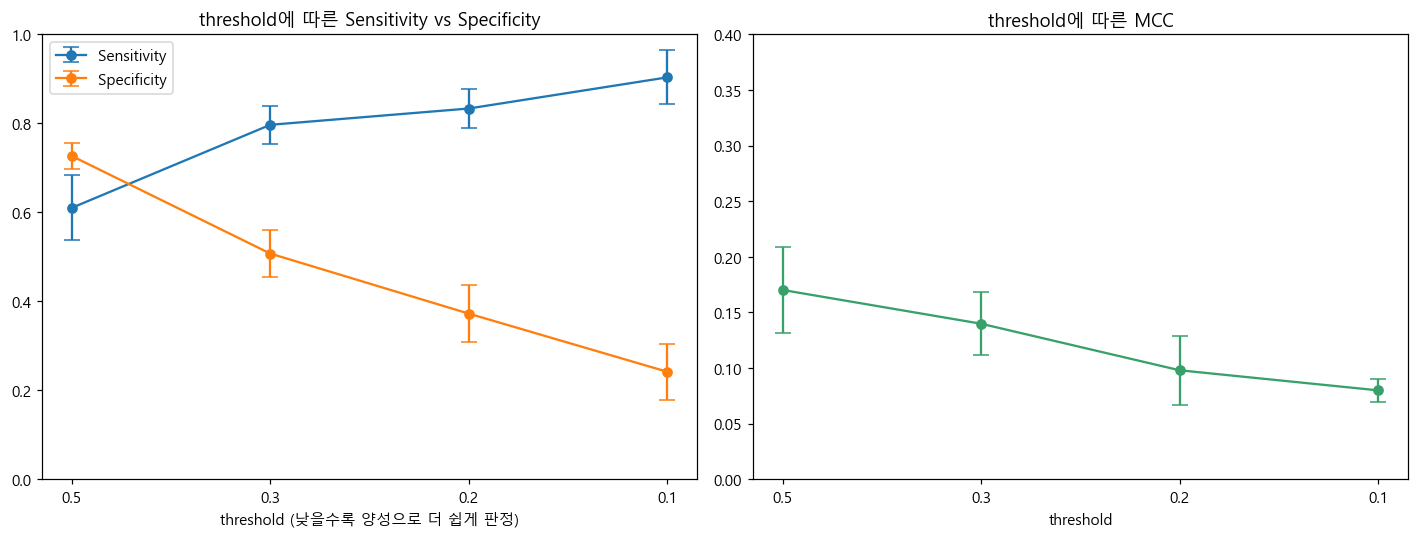

In [3]:
import matplotlib.pyplot as plt

labels = [str(t) for t in THRESHOLDS]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for metric, name, ax in [("sensitivity", "Sensitivity", axes[0]), ("specificity", "Specificity", axes[0])]:
    means = [np.mean([r[metric] for r in store[t]]) for t in THRESHOLDS]
    sds = [np.std([r[metric] for r in store[t]]) for t in THRESHOLDS]
    axes[0].errorbar(labels, means, yerr=sds, marker="o", capsize=5, label=name)
axes[0].set_title("threshold에 따른 Sensitivity vs Specificity")
axes[0].set_xlabel("threshold (낮을수록 양성으로 더 쉽게 판정)")
axes[0].legend()
axes[0].set_ylim(0, 1.0)

mcc_means = [np.mean([r["mcc"] for r in store[t]]) for t in THRESHOLDS]
mcc_sds = [np.std([r["mcc"] for r in store[t]]) for t in THRESHOLDS]
axes[1].errorbar(labels, mcc_means, yerr=mcc_sds, marker="o", capsize=5, color="#38a169")
axes[1].set_title("threshold에 따른 MCC")
axes[1].set_xlabel("threshold")
axes[1].set_ylim(0, 0.4)

plt.tight_layout()
plt.show()

## 판단

In [4]:
print("요약 (반복 10회, nz20, group-aware val):")
for th in THRESHOLDS:
    a = B.agg(store[th])
    print(" ", B.fmt_agg(a, f"threshold={th}"))

base = store[0.5]
for th in THRESHOLDS[1:]:
    cand = store[th]
    d_sens = np.array([r["sensitivity"] for r in cand]) - np.array([r["sensitivity"] for r in base])
    d_spec = np.array([r["specificity"] for r in cand]) - np.array([r["specificity"] for r in base])
    d_mcc = np.array([r["mcc"] for r in cand]) - np.array([r["mcc"] for r in base])
    print(f"\n0.5 -> {th}: Sens {d_sens.mean():+.3f}(sd{d_sens.std():.3f}), "
          f"Spec {d_spec.mean():+.3f}(sd{d_spec.std():.3f}), MCC {d_mcc.mean():+.3f}(sd{d_mcc.std():.3f})")

요약 (반복 10회, nz20, group-aware val):
  threshold=0.5            Sens 0.610±0.073 Spec 0.727±0.030 격차 0.127±0.065 MCC 0.170±0.039 AUC 0.722±0.030
  threshold=0.3            Sens 0.797±0.043 Spec 0.507±0.053 격차 0.289±0.074 MCC 0.140±0.028 AUC 0.722±0.030
  threshold=0.2            Sens 0.833±0.045 Spec 0.372±0.064 격차 0.461±0.086 MCC 0.098±0.031 AUC 0.722±0.030
  threshold=0.1            Sens 0.903±0.060 Spec 0.241±0.062 격차 0.662±0.121 MCC 0.080±0.010 AUC 0.722±0.030

0.5 -> 0.3: Sens +0.187(sd0.087), Spec -0.219(sd0.030), MCC -0.030(sd0.037)

0.5 -> 0.2: Sens +0.223(sd0.088), Spec -0.354(sd0.043), MCC -0.072(sd0.041)

0.5 -> 0.1: Sens +0.293(sd0.101), Spec -0.485(sd0.043), MCC -0.090(sd0.043)


## 정리

- threshold를 낮추면 Sensitivity는 오르지만 Specificity가 떨어지는 전형적인 트레이드오프를 확인합니다.
- "공짜 개선"은 없습니다 — 어느 threshold가 우리 목적(자극성을 놓치지 않는 것 우선 vs 균형)에 맞는지는
  팀 판단이 필요합니다.
- 팀원 결론과 마찬가지로, **근본적인 개선은 threshold 조정이 아니라 양성 데이터 추가 확보**입니다.
  threshold 조정은 "있는 모델을 어떻게 쓸지"의 문제이고, 모델 자체의 변별력(MCC·ROC-AUC)은 바뀌지 않습니다.